# 10°F interval-centroid tangent alignment — temperatures, layer 4

Compare saved **KMeans+PCA** and **MFA-EM (HDDC)** checkpoints at rank thresholds $\tau\in\{0.1,0.01\}$ and component counts $K\in\{50,100\}$.

Each reference point averages **all held-out prompts in a 10°F interval**:
$$\mu_b=\frac{1}{N_b}\sum_{i:b\le T_i<b+10}x_i,\qquad t_b=\frac{\mu_{b+10}-\mu_b}{\|\mu_{b+10}-\mu_b\|}.$$
Intervals are zero-anchored and half-open: **[−40, −30), [−30, −20), …, [110, 120) °F**. Each prompt has equal weight; distinct temperatures are not weighted equally. Nonempty partial intervals are retained; empty intervals are not bridged. The loader floors temperatures into 1°F bins, and the evaluator groups 10 such bins, exactly matching 10°F intervals even for negative and decimal values.

Component weights use every prompt in each endpoint interval, with each endpoint contributing half:
$$w_{b,k}=\tfrac12\Pr(k\mid b)+\tfrac12\Pr(k\mid b+10),\qquad s_b=\sum_k w_{b,k}(t_b^\top v_{k,1})^2.$$
The primary score averages valid segments equally. Undefined PC1s contribute zero while retaining their weight; the conditional score normalizes by pooled identifiable weight.

**Run:** select the repository `.venv` Python kernel, edit the configuration below, then **Run All**. The notebook reuses the existing evaluator; centroids, secants and scores are computed in the analysis modules. No training is performed. Temperature records have no template IDs.

**Evaluation space:** centroids, secants, assignments, and alignment scores use the original 4096-dimensional activation space. The shuffled control uses this same space. PCA is fitted once on all test activations solely for the 3D visualization; Gaussian colors and hover scores report original-space alignment.

**Real vs shuffled:** shuffle labels across prompts and rebuild interval centroids and secants, while preserving the original endpoint assignment weights and model directions. Compare on the common valid segments. One fixed-seed shuffle is a sanity check, not a significance test.

In [1]:
from pathlib import Path
import sys
import os
import gc
import json
import time
from datetime import datetime, timezone

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/dalg").is_dir() and (p / "pyproject.toml").is_file())
for folder in (REPO / "src", REPO / "scripts/temporary"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import evaluate_year_tangent_alignment as evaluator
from evaluate_sae_label_tangents import comparison_plan
from dalg.analysis.label_tangent_alignment import estimate_label_tangents
from dalg.analysis.activation_projection import fit_activation_pca, project_alignment_inputs, project_gaussian_components
from plot_label_tangent_alignment import make_alignment_figure

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Edit these parameters, then rerun all cells.
DATA_ROOT = REPO / "dalg-cache/sae-manifold/sae_manifold_temperature_02d_llama31_8b_last"
LAYER = 4
TAUS = [0.1, 0.01]           # Saved surgery_threshold values, not evaluation-time rank changes.
K_VALUES = [50, 100]        # Use [50] or [100] to evaluate just one component count.
LABEL_FIELD = "fahrenheit"
BIN_WIDTH = 1.0           # Internal label bins in °F; keep at 1 for the physical-unit displays.
BLOCK_SIZE = 10           # Number of 1°F bins per centroid: 10°F intervals.
DEVICE = "cpu"            # Set to "cuda" only inside an appropriate GPU allocation.
BATCH_SIZE = 256
THREADS = 8
SEED = 42
ATOL, RTOL = 1e-12, 1e-10
PCA_COMPONENTS = 3        # Visualization only; evaluation uses all activation dimensions.
OUTPUT_BASE = REPO / "outputs/experiments/temperature_centroid_alignment_original_space"

torch.set_num_threads(min(THREADS, len(os.sched_getaffinity(0))))
TEST_DIR = DATA_ROOT / "test"
COLORS = {"hddc": "#b34b38", "kmeans": "#236e9f"}
METHOD_NAMES = {"hddc": "HDDC-EM", "kmeans": "KMeans+PCA"}
assert BIN_WIDTH == 1.0, "Physical-unit displays require 1°F internal label bins"

## Select the saved runs

Selection uses checkpoint configuration values, not filename guesses. The regular `*_hddc_em` and `*_kmeans_pca` experiment folders are paired by layer, K, and threshold; the separately named `q1...SKIP` experiment is not included. Every requested pair must exist.

In [3]:
plan = [item for item in comparison_plan([DATA_ROOT])
        if item["layer"] == LAYER and item["K"] in K_VALUES and item["threshold"] in TAUS]
expected = {(k, tau) for k in K_VALUES for tau in TAUS}
assert {(p["K"], p["threshold"]) for p in plan} == expected, "Missing requested saved model pair"
assert len(plan) == len(expected), "Ambiguous model selection"
plan.sort(key=lambda p: (K_VALUES.index(p["K"]), TAUS.index(p["threshold"])))
plan_table = pd.DataFrame(plan)[["name", "layer", "K", "threshold", "kmeans_run", "hddc_run"]]
display(plan_table.rename(columns={"threshold": "tau"}))

,name,layer,K,tau,kmeans_run,hddc_run
0,temperature_l04_k50_threshold0.1,4,50,0.10,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...
1,temperature_l04_k50_threshold0.01,4,50,0.01,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...
2,temperature_l04_k100_threshold0.1,4,100,0.10,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...
3,temperature_l04_k100_threshold0.01,4,100,0.01,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...


## Inspect held-out interval coverage

All held-out prompts contribute to their 10°F interval centroid and assignment weights. The table shows interval boundaries, actual centroid endpoints, and prompt counts. Missing individual temperatures within an interval are allowed. Partial intervals are retained; empty intervals are not bridged. Centroid coordinates in the table are PCA3 display coordinates; the evaluator uses full-dimensional centroids.

In [4]:
first = plan[0]
inputs = evaluator.load_inputs(Path(first["kmeans_run"]), Path(first["hddc_run"]),
                               TEST_DIR, BATCH_SIZE, label_field=LABEL_FIELD, bin_width=BIN_WIDTH)

## Prepare PCA for visualization only

Fit one centered PCA to all test activations for the 3D display. This basis is shared by every model pair. Centroids and secants are computed in the original activation space; their coordinates are projected only for display. PCA does not change evaluation scores or component eligibility.

In [5]:
projection = fit_activation_pca(inputs["activations"], n_components=PCA_COMPONENTS)
projected_activations, _ = project_alignment_inputs(inputs["activations"], {}, projection)
print(f"Visualization PCA: {projection['input_dimension']} -> {projection['dimension']} dimensions")
print(f"Retained variance: {projection['retained_variance_fraction']:.2%}")
display(pd.DataFrame({"PC": range(1, PCA_COMPONENTS + 1),
                      "explained_variance_ratio": projection["explained_variance_ratio"].tolist()}))

Visualization PCA: 4096 -> 3 dimensions
Retained variance: 72.55%


,PC,explained_variance_ratio
0,1,0.444651
1,2,0.199558
2,3,0.081325


Test data: 3,000 prompts, 16 interval centroids
Interval centroids: 15 valid secants
Exclusions: {'missing_next_year': 0, 'insufficient_samples': 0, 'degenerate_difference': 0}


,interval_start_fahrenheit,interval_end_exclusive_fahrenheit,prompt_count
0,-40,-30,24
1,-30,-20,192
2,-20,-10,210
3,-10,0,148
4,0,10,185
5,10,20,207
6,20,30,204
7,30,40,196
8,40,50,213
9,50,60,204


,first_interval,second_interval,start_count,end_count,start_centroid_display_pca3,end_centroid_display_pca3
0,"[-40, -30) °F","[-30, -20) °F",24,192,"[0.6745036663790143, 0.27054334260775414, -0.0...","[0.6528823324638531, 0.24406994375644925, -0.0..."
1,"[-30, -20) °F","[-20, -10) °F",192,210,"[0.6528823324638531, 0.24406994375644925, -0.0...","[0.6853580371838706, 0.18661432826587235, 0.02..."
2,"[-20, -10) °F","[-10, 0) °F",210,148,"[0.6853580371838706, 0.18661432826587235, 0.02...","[0.6849376245325918, 0.1264481217975795, 0.092..."
3,"[-10, 0) °F","[0, 10) °F",148,185,"[0.6849376245325918, 0.1264481217975795, 0.092...","[0.09797628038679645, -0.4330618864359007, 0.2..."
4,"[0, 10) °F","[10, 20) °F",185,207,"[0.09797628038679645, -0.4330618864359007, 0.2...","[0.07376551513271774, -0.40261205524804106, 0...."
5,"[10, 20) °F","[20, 30) °F",207,204,"[0.07376551513271774, -0.40261205524804106, 0....","[0.0184581459773404, -0.3283615230641683, -0.0..."
6,"[20, 30) °F","[30, 40) °F",204,196,"[0.0184581459773404, -0.3283615230641683, -0.0...","[-0.04619688063489308, -0.24410565989254268, -..."
7,"[30, 40) °F","[40, 50) °F",196,213,"[-0.04619688063489308, -0.24410565989254268, -...","[-0.0964054374536784, -0.15049984294075947, -0..."
8,"[40, 50) °F","[50, 60) °F",213,204,"[-0.0964054374536784, -0.15049984294075947, -0...","[-0.15694091836717852, -0.024083524395280415, ..."
9,"[50, 60) °F","[60, 70) °F",204,212,"[-0.15694091836717852, -0.024083524395280415, ...","[-0.20753233484346545, 0.07068673291124897, -0..."


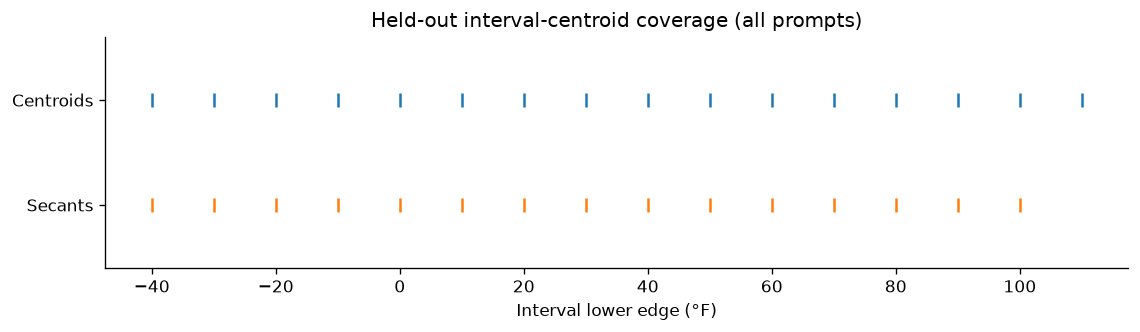

In [6]:
records = inputs["records"]
prompt_table = pd.DataFrame({
    "fahrenheit": [r["labels"]["fahrenheit"] for r in records],
    "prompt": [r["prompt"] for r in records],
})
reference = estimate_label_tangents(inputs["activations"], inputs["years"],
                                    block_size=BLOCK_SIZE, atol=ATOL, rtol=RTOL)
# Project the evaluated centroids without rebuilding or filtering the secants.
plot_reference = {key: reference[key] for key in ("years", "counts", "block_size", "endpoint_indices", "segment_years")}
plot_reference["means"], _ = project_alignment_inputs(reference["means"], {}, projection)
EVALUATION_DIMENSION = inputs["activations"].shape[1]
assert reference["tangents"].shape[1] == EVALUATION_DIMENSION
assert len(reference["segment_years"]), "No valid successive-interval centroid pairs"
print(f"Test data: {len(records):,} prompts, {len(reference['years']):,} interval centroids")
print(f"Interval centroids: {len(reference['segment_years'])} valid secants")
print("Exclusions:", reference["exclusions"])
coverage = pd.DataFrame({
    "interval_start_fahrenheit": reference["years"].tolist(),
    "interval_end_exclusive_fahrenheit": (reference["years"] + BLOCK_SIZE).tolist(),
    "prompt_count": reference["counts"].tolist(),
})
display(coverage)
endpoint_indices = reference["endpoint_indices"].tolist()
display(pd.DataFrame([
    {"first_interval": f"[{int(reference['years'][a])}, {int(reference['years'][a]) + BLOCK_SIZE}) °F",
     "second_interval": f"[{int(reference['years'][b])}, {int(reference['years'][b]) + BLOCK_SIZE}) °F",
     "start_count": int(reference["counts"][a]), "end_count": int(reference["counts"][b]),
     "start_centroid_display_pca3": plot_reference["means"][a].tolist(),
     "end_centroid_display_pca3": plot_reference["means"][b].tolist()}
    for a, b in endpoint_indices
]))
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.scatter(reference["years"], np.ones(len(reference["years"])), marker="|", s=70)
ax.scatter(reference["segment_years"], np.zeros(len(endpoint_indices)), marker="|", s=70)
ax.set(xlabel="Interval lower edge (°F)", yticks=[0, 1], yticklabels=["Secants", "Centroids"], ylim=(-0.6, 1.6),
       title="Held-out interval-centroid coverage (all prompts)")
plt.show()

## Run the evaluation

Each pair uses the same interval-centroid secants and all prompts in both endpoint intervals for weights. The shuffled control permutes labels across **all held-out prompts**, then recomputes interval centroids; evaluation labels and assignments stay fixed. Real-versus-control comparisons use their shared valid segments.

This evaluation uses one reference population, so cross-fit reference agreement is not defined. The shuffle is one control realization, not a significance test. The legacy `evaluate_template_alignment` entrypoint calls the centroid method and ignores template selection.

This cell reruns the requested comparisons and creates a new output directory on each execution. Detailed JSON reports retain interval counts, centroid endpoint indices, exclusions, component diagnostics, and source provenance.

Pass raw activations and original model PC1s directly to the evaluator. Afterwards, project geometry for display while retaining the original-space component scores and eligibility. A direction with a vanishing display projection has no visible line, but keeps its original evaluation score. The saved PCA artifact describes visualization only.

In [7]:
RUN_DIR = OUTPUT_BASE / (
    f"layer{LAYER:02d}_original_space_block{reference['block_size']}_centroids_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ"))
RUN_DIR.mkdir(parents=True, exist_ok=False)
settings = dict(layer=LAYER, taus=TAUS, K_values=K_VALUES, reference_kind="block_centroids", block_size=reference["block_size"],
                label_field=LABEL_FIELD, label_unit="°F", bin_width=BIN_WIDTH, interval_width_fahrenheit=BIN_WIDTH * BLOCK_SIZE,
                device=DEVICE, batch_size=BATCH_SIZE, threads=torch.get_num_threads(),
                seed=SEED, atol=ATOL, rtol=RTOL, data_root=str(DATA_ROOT.resolve()),
                evaluation_population="all held-out endpoint-block prompts", comparisons=plan,
                evaluation_space="raw fitted shard space", evaluation_dimension=EVALUATION_DIMENSION,
                visualization_projection=evaluator._jsonable({k: v for k, v in projection.items() if k not in ("mean", "basis")}),
                visualization_pca_fitting_population="all test activations")
coverage.to_csv(RUN_DIR / "interval_coverage.csv", index=False)
(RUN_DIR / "comparison_plan.json").write_text(json.dumps(settings, indent=2) + "\n")
torch.save(projection, RUN_DIR / "visualization_pca_projection.pt")
reports = {}
plot_comparisons = {}
summary_rows, segment_rows = [], []
for i, item in enumerate(plan):
    started = time.monotonic()
    print(f"[{i + 1}/{len(plan)}] layer={LAYER}, K={item['K']}, tau={item['threshold']:g}", flush=True)
    # The first load above is reused; later pairs run the same provenance checks.
    if i > 0 or "inputs" not in globals():
        inputs = evaluator.load_inputs(Path(item["kmeans_run"]), Path(item["hddc_run"]),
                                       TEST_DIR, BATCH_SIZE, label_field=LABEL_FIELD, bin_width=BIN_WIDTH)
    geometry = evaluator.model_geometry_and_assignments(inputs["models"], inputs["activations"],
                                                        DEVICE, BATCH_SIZE)
    assert all(g["pc1"].shape[1] == EVALUATION_DIMENSION for g in geometry.values())
    report = evaluator.evaluate_template_alignment(
        inputs["activations"], inputs["years"], inputs["templates"], geometry,
        template_id=None, block_size=BLOCK_SIZE, seed=SEED, atol=ATOL, rtol=RTOL)
    assert torch.equal(report["segment_years"], reference["segment_years"])
    report["provenance"] = dict(inputs["provenance"], label_unit="°F",
                                interval_width_fahrenheit=BLOCK_SIZE * BIN_WIDTH,
                                representation="raw fitted shard space", evaluation_dimension=EVALUATION_DIMENSION,
                                assignment_representation="raw fitted shard space")
    # Display projection never enters the evaluator or its component diagnostics.
    _, display_geometry = project_alignment_inputs(inputs["activations"], geometry, projection)
    report["visualization_projection"] = dict(settings["visualization_projection"],
        fitting_population="all test activations", purpose="display only",
        artifact="visualization_pca_projection.pt",
        pc1_projection_squared_norm={kind: g["pc1_projection_squared_norm"] for kind, g in display_geometry.items()})
    report["prompt_distribution"] = evaluator.prompt_distribution(
        inputs["records"], report["fold_rows"], inputs["years"])
    reports[item["name"]] = report
    for kind in ("hddc", "kmeans"):
        label = f"{METHOD_NAMES[kind]} | K={item['K']} | tau={item['threshold']:g}"
        plot_comparisons[label] = dict(
            gaussians=project_gaussian_components(inputs["models"][kind], kind, projection),
            components=report["methods"][kind]["folds"][0]["components"],
            pc1=display_geometry[kind]["pc1"],
            pc1_visible=display_geometry[kind]["identifiable"])
    (RUN_DIR / f"{item['name']}.json").write_text(
        json.dumps(evaluator._jsonable(report), indent=2, allow_nan=False) + "\n")
    for kind, result in report["methods"].items():
        summary_rows.append(dict(
            name=item["name"], layer=LAYER, K=item["K"], tau=item["threshold"], method=kind,
            reference_kind="block_centroids", block_size=reference["block_size"],
            label_field=LABEL_FIELD, interval_width_fahrenheit=BLOCK_SIZE * BIN_WIDTH,
            evaluation_space="raw fitted shard space", evaluation_dimension=EVALUATION_DIMENSION, segments=len(report["segment_years"]),
            control_segments=len(report["negative_control"]["segment_years"]),
            **{key: result[key] for key in ("score", "conditional_score", "unidentified_weight",
                "eligible_component_fraction", "negative_control_score", "matched_real_score")}))
    for j, interval_start in enumerate(report["segment_years"].tolist()):
        h = float(report["methods"]["hddc"]["segment_scores"][j])
        k = float(report["methods"]["kmeans"]["segment_scores"][j])
        segment_rows.append(dict(name=item["name"], K=item["K"], tau=item["threshold"],
                                 interval_start_fahrenheit=interval_start,
                                 next_interval_start_fahrenheit=interval_start + BLOCK_SIZE,
                                 hddc=h, kmeans=k, difference=h-k))
    print(f"  {len(report['segment_years'])} segments; "
          f"HDDC={report['methods']['hddc']['score']:.6f}, "
          f"KMeans={report['methods']['kmeans']['score']:.6f}; "
          f"{time.monotonic() - started:.1f}s", flush=True)
    del inputs, geometry, display_geometry
    gc.collect()
summary = pd.DataFrame(summary_rows)
segments = pd.DataFrame(segment_rows)
summary.to_csv(RUN_DIR / "summary.csv", index=False)
segments.to_csv(RUN_DIR / "segments.csv", index=False)
print("Saved results:", RUN_DIR)
display(summary[["K", "tau", "method", "segments", "score", "conditional_score",
                 "unidentified_weight", "negative_control_score", "matched_real_score"]])

[1/4] layer=4, K=50, tau=0.1


  15 segments; HDDC=0.154245, KMeans=0.102213; 3.3s


[2/4] layer=4, K=50, tau=0.01


  15 segments; HDDC=0.163830, KMeans=0.102213; 4.1s


[3/4] layer=4, K=100, tau=0.1


  15 segments; HDDC=0.086987, KMeans=0.043173; 7.6s


[4/4] layer=4, K=100, tau=0.01


  15 segments; HDDC=0.099155, KMeans=0.043173; 7.8s


Saved results: /orfeo/cephfs/home/dssc/zenocosini/decomposing-activations-local-geometry/outputs/experiments/temperature_centroid_alignment_original_space/layer04_original_space_block10_centroids_20261111T140450_208249Z


,K,tau,method,segments,score,conditional_score,unidentified_weight,negative_control_score,matched_real_score
0,50,0.10,kmeans,15,0.102213,0.102213,3.700743e-17,0.017506,0.102213
1,50,0.10,hddc,15,0.154245,0.154245,1.480297e-17,0.027759,0.154245
2,50,0.01,kmeans,15,0.102213,0.102213,3.700743e-17,0.017506,0.102213
3,50,0.01,hddc,15,0.163830,0.163830,0.000000e+00,0.026103,0.163830
4,100,0.10,kmeans,15,0.043173,0.043173,7.401487e-18,0.019765,0.043173
5,100,0.10,hddc,15,0.086987,0.086987,7.401487e-18,0.026518,0.086987
6,100,0.01,kmeans,15,0.043173,0.043173,7.401487e-18,0.019765,0.043173
7,100,0.01,hddc,15,0.099155,0.099155,1.480297e-17,0.027373,0.099155


## Mean alignment and shuffled control

The left panels show the primary score. The right panels compare real and shuffled references on the same control-eligible segments. Solid bars are real; hatched bars are shuffled. Scores are squared directional alignments, averaged using the weights above.

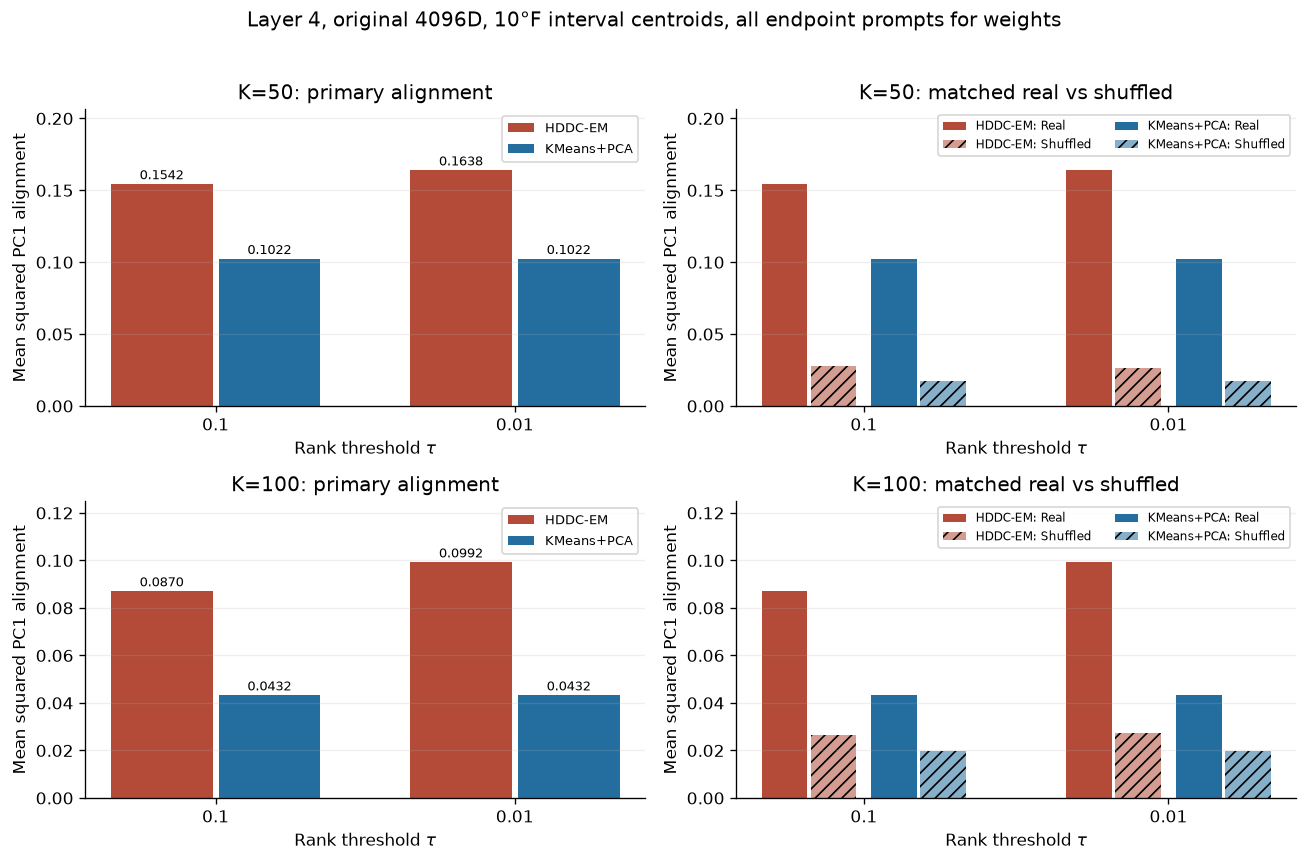

In [8]:
fig, axes = plt.subplots(len(K_VALUES), 2, figsize=(11, 3.5 * len(K_VALUES)), squeeze=False)
x = np.arange(len(TAUS))
for row, k in enumerate(K_VALUES):
    ax, control_ax = axes[row]
    for offset, kind in enumerate(("hddc", "kmeans")):
        table = summary[(summary.K == k) & (summary.method == kind)].set_index("tau").loc[TAUS]
        centers = x + (offset - 0.5) * 0.36
        ax.bar(centers, table.score, width=0.34, color=COLORS[kind], label=METHOD_NAMES[kind])
        for center, score in zip(centers, table.score):
            ax.annotate(f"{score:.4f}", (center, score), xytext=(0, 3), textcoords="offset points",
                        ha="center", fontsize=8)
        for shift, field, hatch, alpha, label in (
            (-0.08, "matched_real_score", "", 1., "Real"),
            (0.08, "negative_control_score", "///", 0.55, "Shuffled"),
        ):
            control_ax.bar(centers + shift, table[field], width=0.15,
                           color=COLORS[kind], hatch=hatch, alpha=alpha,
                           label=f"{METHOD_NAMES[kind]}: {label}")
    for axis in (ax, control_ax):
        axis.set(xticks=x, xticklabels=[f"{tau:g}" for tau in TAUS], xlabel=r"Rank threshold $\tau$",
                 ylabel="Mean squared PC1 alignment")
        axis.set_ylim(0, axis.get_ylim()[1] * 1.2)
        axis.grid(axis="y", alpha=.2)
    ax.set_title(f"K={k}: primary alignment")
    control_ax.set_title(f"K={k}: matched real vs shuffled")
    ax.legend(fontsize=8)
    control_ax.legend(fontsize=7, ncols=2)
fig.suptitle(f"Layer {LAYER}, original {EVALUATION_DIMENSION}D, {BLOCK_SIZE:g}°F interval centroids, all endpoint prompts for weights", y=1.02)
fig.tight_layout()
fig.savefig(RUN_DIR / "mean_alignment.png", dpi=180, bbox_inches="tight")
fig.savefig(RUN_DIR / "mean_alignment.pdf", bbox_inches="tight")
plt.show()

## Alignment along the interval axis

Points show only observed valid segments; lines are omitted so empty intervals remain visible. Each column uses the same vertical scale.

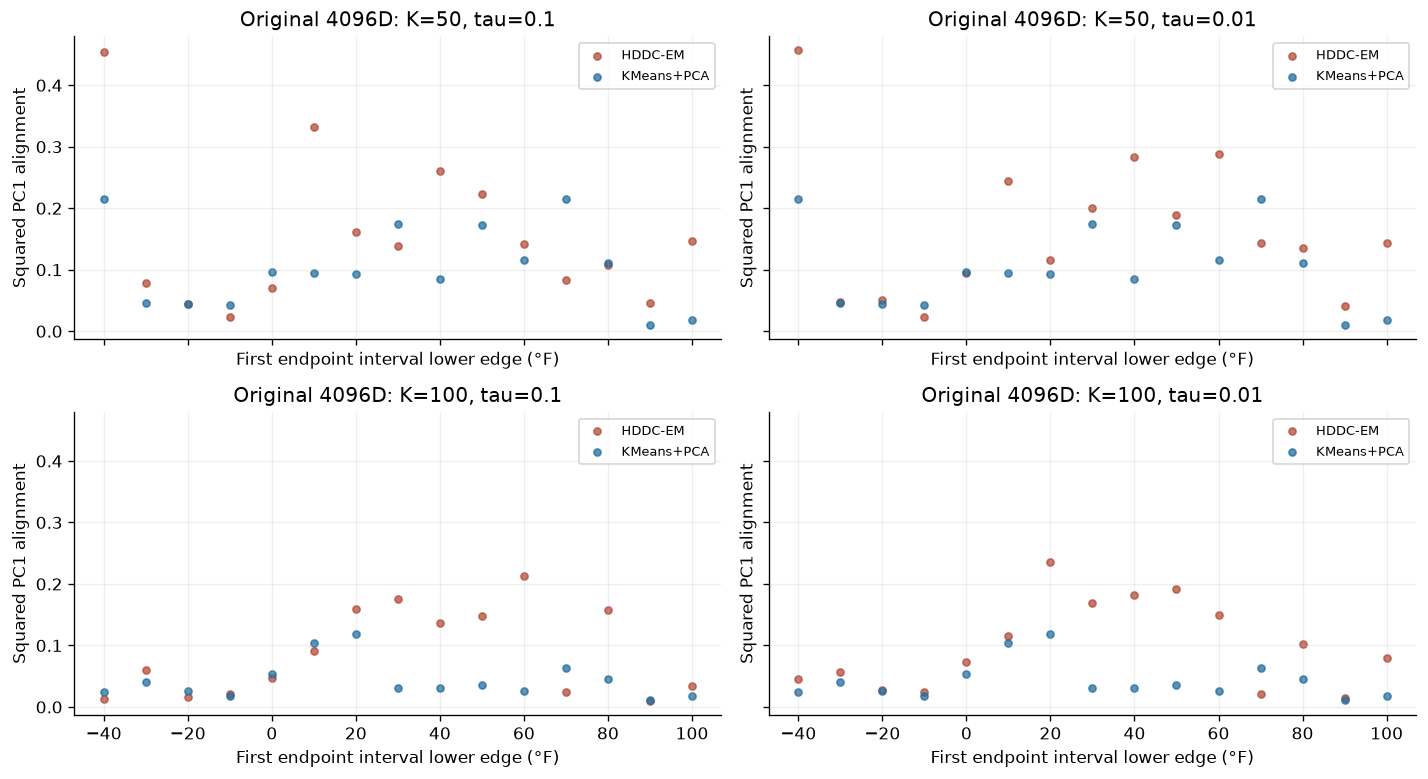

In [9]:
fig, axes = plt.subplots(len(K_VALUES), len(TAUS), figsize=(12, 3.3 * len(K_VALUES)),
                         squeeze=False, sharex=True, sharey=True)
for i, k in enumerate(K_VALUES):
    for j, tau in enumerate(TAUS):
        ax = axes[i, j]
        table = segments[(segments.K == k) & (segments.tau == tau)]
        for kind in ("hddc", "kmeans"):
            ax.scatter(table.interval_start_fahrenheit, table[kind], s=18, alpha=.75,
                       color=COLORS[kind], label=METHOD_NAMES[kind])
        ax.set(title=f"Original {EVALUATION_DIMENSION}D: K={k}, tau={tau:g}", xlabel="First endpoint interval lower edge (°F)", ylabel="Squared PC1 alignment")
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN_DIR / "alignment_by_temperature.png", dpi=180)
fig.savefig(RUN_DIR / "alignment_by_temperature.pdf")
plt.show()

## Paired differences

Positive differences favor HDDC; negative differences favor KMeans+PCA. The zero line marks equal alignment. The summary below gives the mean difference and the fraction of segments with higher HDDC alignment, without treating dependent segments as independent statistical replicates.

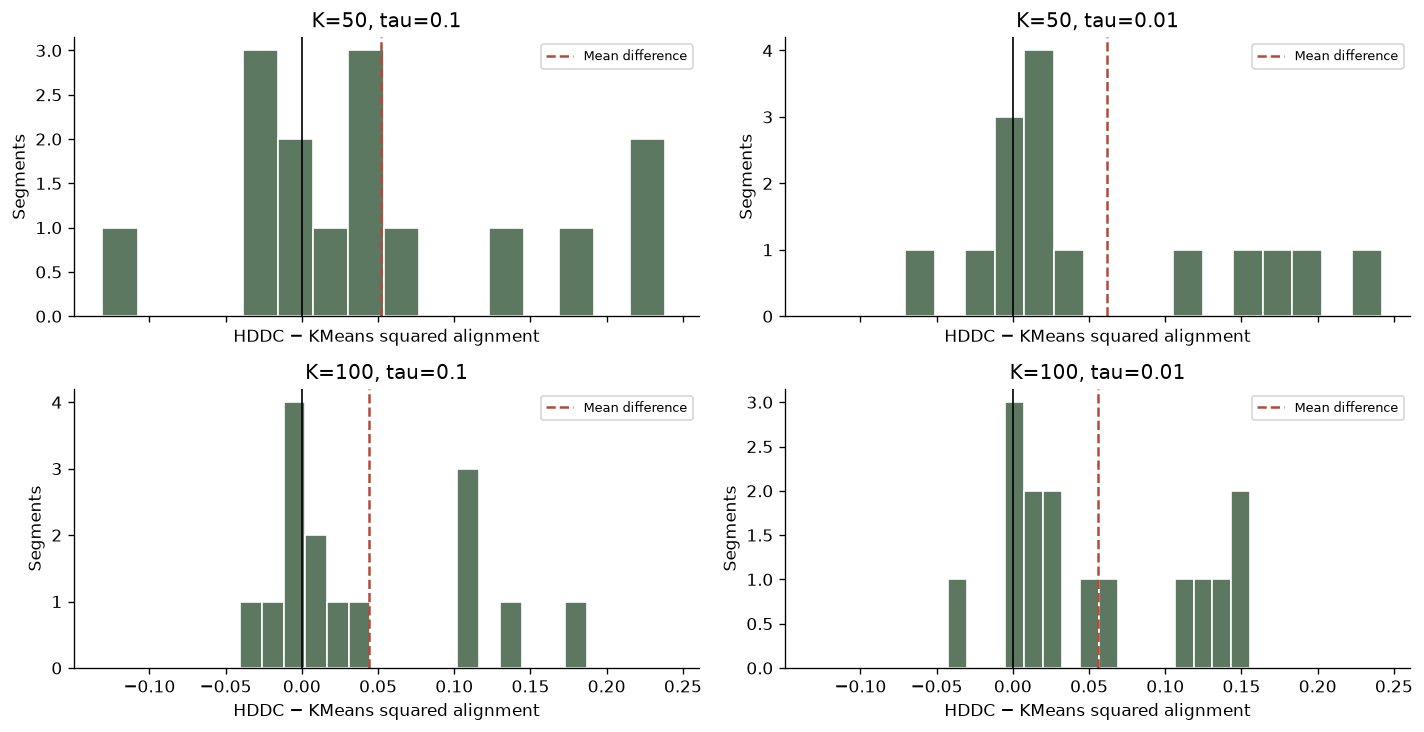

,K,tau,mean_difference,median_difference,hddc_higher_fraction,segments
0,50,0.10,0.052032,0.032561,0.666667,15
1,50,0.01,0.061617,0.023162,0.800000,15
2,100,0.10,0.043814,0.015839,0.600000,15
3,100,0.01,0.055983,0.021518,0.933333,15


Artifacts: /orfeo/cephfs/home/dssc/zenocosini/decomposing-activations-local-geometry/outputs/experiments/temperature_centroid_alignment_original_space/layer04_original_space_block10_centroids_20261111T140450_208249Z
Reference: all-prompt 10°F interval centroids.


In [10]:
fig, axes = plt.subplots(len(K_VALUES), len(TAUS), figsize=(12, 3.1 * len(K_VALUES)),
                         squeeze=False, sharex=True)
paired_rows = []
for i, k in enumerate(K_VALUES):
    for j, tau in enumerate(TAUS):
        table = segments[(segments.K == k) & (segments.tau == tau)]
        ax = axes[i, j]
        ax.hist(table.difference, bins=16, color="#5c7860", edgecolor="white")
        ax.axvline(0, color="black", linewidth=1)
        ax.axvline(table.difference.mean(), color=COLORS["hddc"], linestyle="--", label="Mean difference")
        ax.set(title=f"K={k}, tau={tau:g}", xlabel="HDDC − KMeans squared alignment", ylabel="Segments")
        ax.legend(fontsize=8)
        paired_rows.append(dict(K=k, tau=tau, mean_difference=table.difference.mean(),
                                median_difference=table.difference.median(),
                                hddc_higher_fraction=(table.difference > 1e-12).mean(),
                                segments=len(table)))
fig.tight_layout()
fig.savefig(RUN_DIR / "paired_differences.png", dpi=180)
fig.savefig(RUN_DIR / "paired_differences.pdf")
plt.show()
paired_summary = pd.DataFrame(paired_rows)
paired_summary.to_csv(RUN_DIR / "paired_summary.csv", index=False)
display(paired_summary)
print("Artifacts:", RUN_DIR)
print(f"Reference: all-prompt {BLOCK_SIZE:g}°F interval centroids.")

## Interactive data, interval centroids, Gaussian components, and secants

Use the dropdown to select model, K, and τ. Drag to rotate and scroll to zoom. The legend toggles data, interval centroids, and centroid secants. Blue points are interval centroids; orange segments connect the centroids used by evaluation. Hover over a centroid for its temperature range and prompt count. Hover over an ellipsoid or its center for the **component ID** and **alignment**, plus its contribution and assignment mass.

Ellipsoid color and hover alignment show the component's assignment-weighted mean squared alignment:
$A_k=\sum_s w_{s,k}(t_s^\top v_{k,1})^2 / \sum_s w_{s,k}$.
Undefined scores are gray. Scores use secants and **original PC1 directions in the full activation space**. The 3D angles can differ from the angles used to compute these scores.

The ellipsoids are probability regions of the **3D marginal Gaussian**, using projected full covariances. HDDC includes all fitted loadings and noise; KMeans uses the repository's Gaussian approximation from saved cluster PCA, including residual noise. The probability below controls display size only and does not change the evaluation.

**Thin dotted red lines** show each identifiable component's evaluated PC1, passing through its center and ending at the displayed ellipsoid surface. These lines project the original PC1 directions into global PCA3 for display only. Directions with vanishing projections have no visible line; their full-space evaluation is unchanged. Hover for component ID and alignment; toggle **Evaluated PC1** in the legend to hide the lines.

In [11]:
ELLIPSOID_PROBABILITY = 0.50
ELLIPSOID_OPACITY = 0.12

interactive_alignment = make_alignment_figure(
    projected_activations, prompt_table["fahrenheit"].tolist(), None,
    prompt_table["prompt"].tolist(), plot_reference, plot_comparisons,
    probability=ELLIPSOID_PROBABILITY, opacity=ELLIPSOID_OPACITY, label_field=LABEL_FIELD,
    alignment_space=f"original {EVALUATION_DIMENSION}D")
interactive_path = RUN_DIR / "interactive_alignment_3d.html"
interactive_alignment.write_html(interactive_path, include_plotlyjs=True)
interactive_alignment.show()
print("Standalone interactive plot:", interactive_path)

Standalone interactive plot: /orfeo/cephfs/home/dssc/zenocosini/decomposing-activations-local-geometry/outputs/experiments/temperature_centroid_alignment_original_space/layer04_original_space_block10_centroids_20261111T140450_208249Z/interactive_alignment_3d.html
